# HotZone Stability Analysis — KVS Reproducibility Pipeline
Based on Kristel Van Steen's (KVS) review comments (29 June 2026) on the HotZone paper.

This notebook implements her appendix code, blocks 1-10, wired to your **real** 20-replicate output
(`run_1` ... `run_N` folders from `hotzone_run.py`), instead of her illustrative mock data.

**Runtime:** In Google Colab, set `Runtime > Change runtime type > R` before running this notebook.

---
### A note on accuracy (read before running)
I kept every block as close to KVS's original code as possible. Three changes were necessary purely to make it *run* - not stylistic choices:

1. **Frequency histogram (Block 4):** her code used `linestyle =` inside `geom_vline()`, which is not a valid ggplot2 argument (it's `linetype =`). Fixed the argument name only.
2. **Global density scatter (Block 10):** her code used `color = ..black..`, which is invalid/deprecated ggplot2 internal syntax. Changed to `color = "black"` (a fixed color, not mapped to data - same visual intent she described).
3. **Hardcoded thresholds:** her code assumed exactly 20 runs (e.g. `xintercept = 16.5`, `consistency_score >= 17`, `n_genes` comment "Exactly 350"). I generalized these to use `n_runs` / `nrow(binary_matrix)` computed from your actual uploaded data, so the >=80% threshold and gene universe size are correct however many runs/genes you actually have. The *logic* (80% cutoff, SMC/MCC formulas, Fiedler/variance criteria) is unchanged.

Everything else - variable names, plot styling, function structure - matches her document as written.


## 0. Install & load required packages

In [ ]:
install_if_missing <- function(pkg, bioc = FALSE) {
  if (!requireNamespace(pkg, quietly = TRUE)) {
    if (bioc) {
      if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager")
      BiocManager::install(pkg, update = FALSE, ask = FALSE)
    } else {
      install.packages(pkg)
    }
  }
}

install_if_missing("ggplot2")
install_if_missing("vegan")
install_if_missing("circlize")
install_if_missing("ComplexHeatmap", bioc = TRUE)
install_if_missing("biomaRt", bioc = TRUE)

library(ggplot2)
library(vegan)
library(circlize)
library(ComplexHeatmap)
library(biomaRt)

cat("All packages loaded.\n")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘permute’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘GlobalOptions’, ‘shape’, ‘colorspace’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.0 (2026-04-24)

Installing package(s) 'BiocVersion', 'ComplexHeatmap'

also installing the dependencies ‘rjson’, ‘BiocGenerics’, ‘S4Vectors’, ‘iterators’, ‘GetoptLong’, ‘clue’, ‘png’, ‘IRanges’, ‘matrixStats’, ‘foreach’, ‘doParallel’


'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement reposit

All packages loaded.


## 1. Upload your input data

Zip your `run_1`, `run_2`, ..., `run_N` folders into a single archive (e.g. `hotzone_runs.zip`).
Each `run_i` folder should contain the three files `hotzone_run.py` produces:

- `hotzone_genes.csv` (column: `gene`)
- `hotzone_gene_clusters.csv` (columns: `gene`, `cluster`)
- `hotzone_cluster_stats.csv` (columns: `cluster`, `n_genes`, `mean_edge_variance`, `fiedler_value`)

**In Colab:** click the folder icon in the left sidebar -> the upload icon (page with an up-arrow) -> select your zip. Once you see it listed under `/content/`, run the cell below (edit `zip_path` if your filename differs).

In [ ]:
zip_path <- "/content/hotzone_runs.zip"  # <-- change this if your uploaded filename differs

if (!file.exists(zip_path)) {
  stop(paste0("Could not find '", zip_path, "'. Upload it via the Colab Files sidebar first, then re-run this cell."))
}

unzip(zip_path, exdir = "/content/runs")
cat("Unzipped to /content/runs\n")
print(list.dirs("/content/runs", recursive = FALSE))

Unzipped to /content/runs
[1] "/content/runs/hotzone_runs"


## 2. Load your 20 (or N) replicate outputs

In [ ]:
runs_dir <- "/content/runs/hotzone_runs"
run_folders <- sort(list.dirs(runs_dir, recursive = FALSE))
run_folders <- run_folders[grepl("run_", basename(run_folders))]

cat("Found", length(run_folders), "run folders:\n")
print(basename(run_folders))

gene_lists <- list()
clustering_list <- list()
cluster_stats_list <- list()

for (rf in run_folders) {
  run_name <- basename(rf)

  genes_path <- file.path(rf, "hotzone_genes.csv")
  if (file.exists(genes_path)) {
    gene_lists[[run_name]] <- read.csv(genes_path, stringsAsFactors = FALSE)$gene
  } else {
    warning(paste("Missing hotzone_genes.csv in", run_name))
  }

  clusters_path <- file.path(rf, "hotzone_gene_clusters.csv")
  if (file.exists(clusters_path)) {
    cdf <- read.csv(clusters_path, stringsAsFactors = FALSE)
    clustering_list[[run_name]] <- setNames(cdf$cluster, cdf$gene)
  }

  stats_path <- file.path(rf, "hotzone_cluster_stats.csv")
  if (file.exists(stats_path)) {
    cluster_stats_list[[run_name]] <- read.csv(stats_path, stringsAsFactors = FALSE)
  }
}

n_runs <- length(gene_lists)
cat("\nLoaded gene lists for", n_runs, "runs.\n")

Found 20 run folders:
 [1] "run_1"  "run_10" "run_11" "run_12" "run_13" "run_14" "run_15" "run_16"
 [9] "run_17" "run_18" "run_19" "run_2"  "run_20" "run_3"  "run_4"  "run_5" 
[17] "run_6"  "run_7"  "run_8"  "run_9" 

Loaded gene lists for 20 runs.


## 3. Bar charts per replicate - KVS Block 1
"For each replicate you obtain HotZones and for these HotZones the following differences/similarities across replicates may occur (which should be reported): the number of HotZones (clusters), the size of each cluster..."


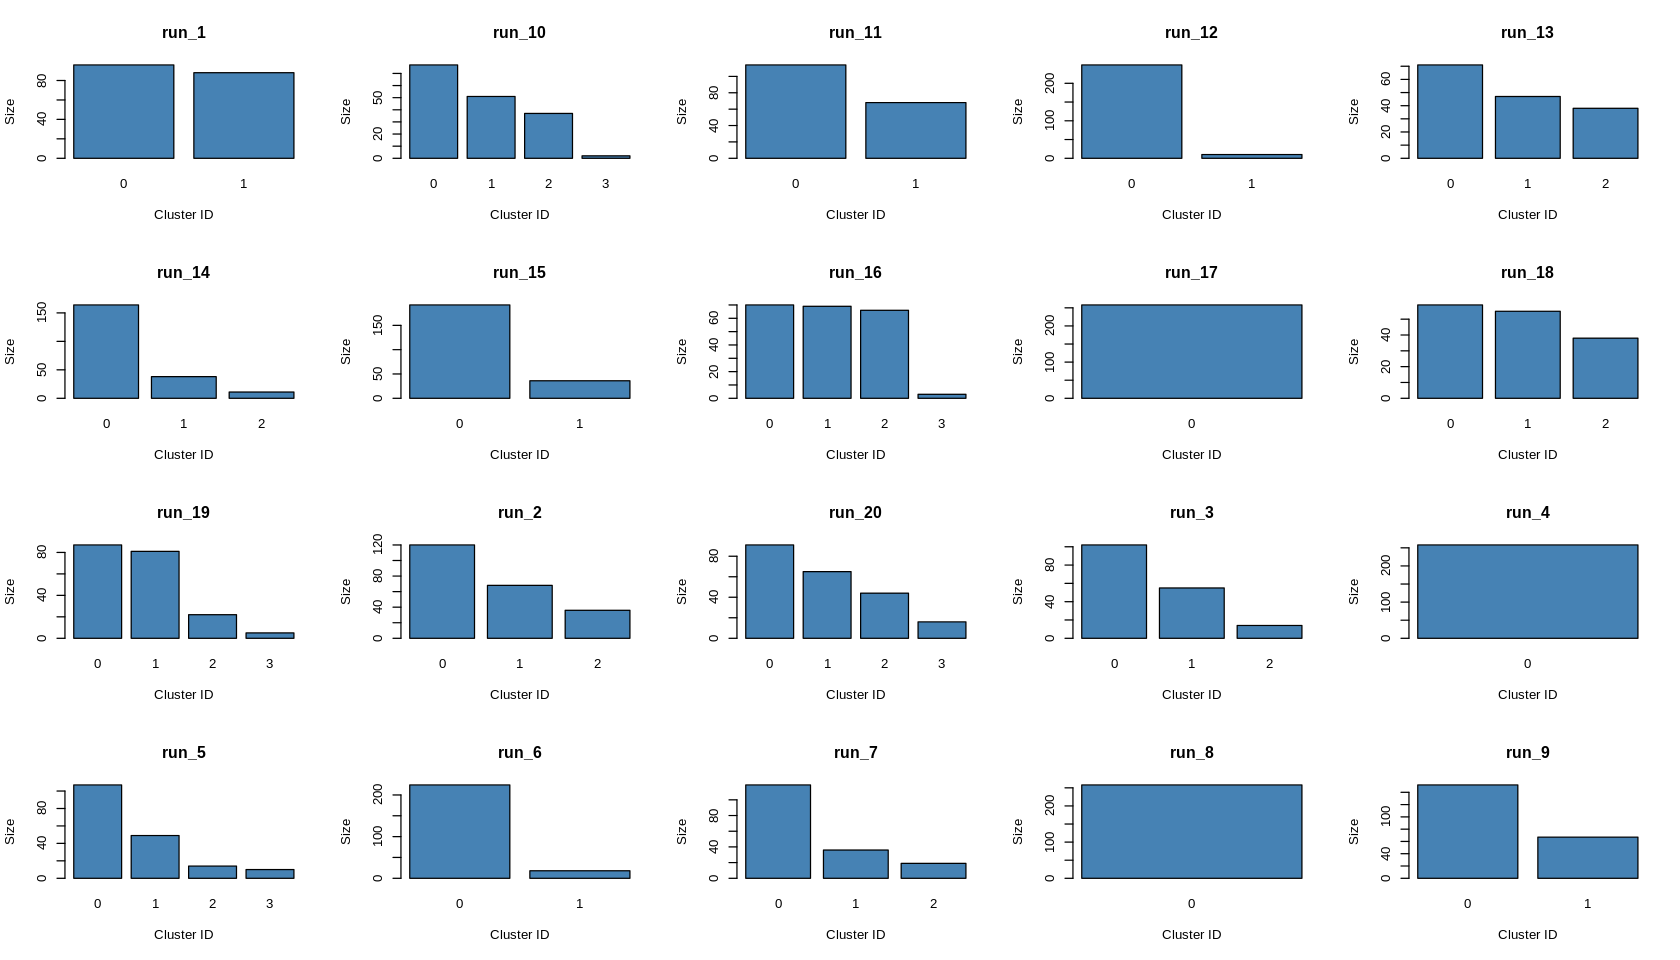

In [ ]:
n_plot_runs <- length(clustering_list)
grid_cols <- ceiling(sqrt(n_plot_runs))
grid_rows <- ceiling(n_plot_runs / grid_cols)
par(mfrow = c(grid_rows, grid_cols))

for (run_name in names(clustering_list)) {
  cluster_sizes <- table(factor(clustering_list[[run_name]]))
  barplot(cluster_sizes,
          main = run_name,
          xlab = "Cluster ID",
          ylab = "Size",
          col = "steelblue",
          border = "black")
}
par(mfrow = c(1, 1))

## 4. Binary gene-presence matrix & consistency scores - KVS Block 2

In [ ]:
unique_genes <- unique(unlist(gene_lists))
binary_matrix <- sapply(gene_lists, function(x) as.numeric(unique_genes %in% x))
rownames(binary_matrix) <- unique_genes
colnames(binary_matrix) <- names(gene_lists)

consistency_score <- rowSums(binary_matrix)

cat("Total unique genes across all runs:", length(unique_genes), "\n")
cat("Number of runs:", n_runs, "\n")

cat("Unique genes appearing in at least one run's HotZone set:", nrow(binary_matrix), "\n")
cat("(Full background universe should be 359 genes total)\n")

Total unique genes across all runs: 358 
Number of runs: 20 
Unique genes appearing in at least one run's HotZone set: 358 
(Full background universe should be 359 genes total)


## 5. Clustered heatmap with consistency annotation - KVS Block 3 (Plot 1)

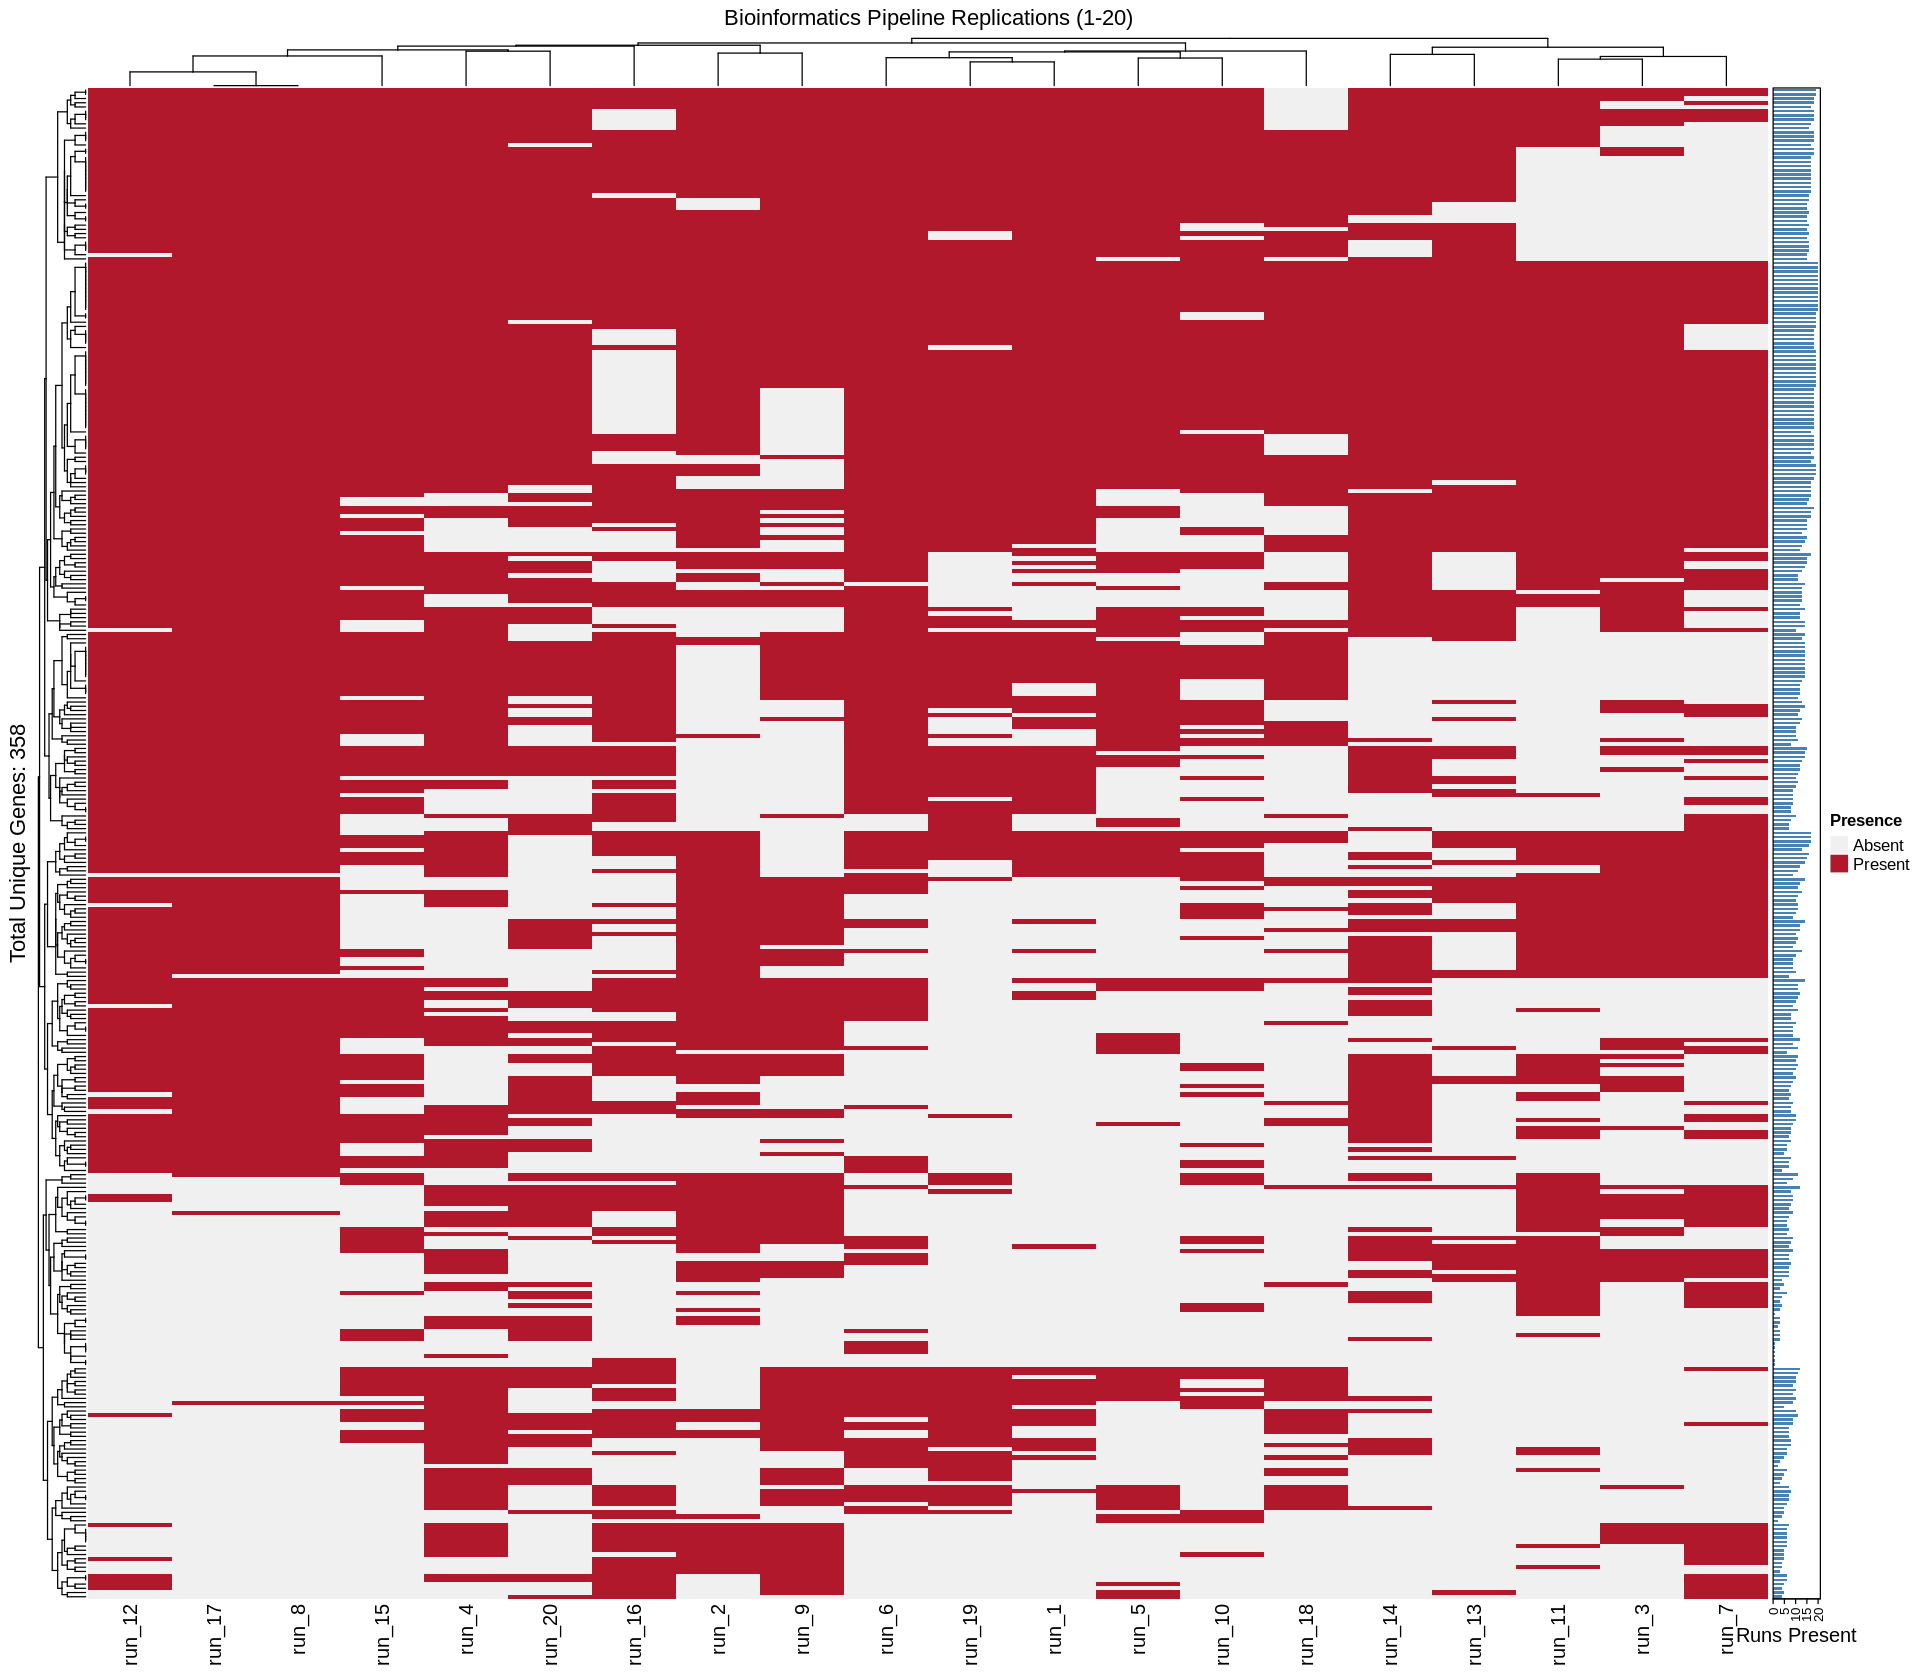

In [ ]:
options(repr.plot.width = 16, repr.plot.height = 14)

row_anno <- rowAnnotation(
  Runs = anno_barplot(
    consistency_score,
    gp = gpar(fill = "steelblue", col = NA),
    axis_param = list(side = "bottom")
  ),
  annotation_label = "Runs Present",
  annotation_name_side = "bottom"
)

ht <- Heatmap(binary_matrix,
        name = "Presence",
        col = c("0" = "#f0f0f0", "1" = "#b2182b"),
        cluster_columns = TRUE,
        cluster_rows = TRUE,
        show_row_names = FALSE,
        right_annotation = row_anno,
        column_title = paste0("Bioinformatics Pipeline Replications (1-", n_runs, ")"),
        row_title = paste("Total Unique Genes:", nrow(binary_matrix)),
        heatmap_legend_param = list(at = c(0, 1), labels = c("Absent", "Present")))

draw(ht)

In [ ]:
## 5b. UpSetR overlap plot - KVS narrative (no original code provided)


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘gridExtra’, ‘plyr’


Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”


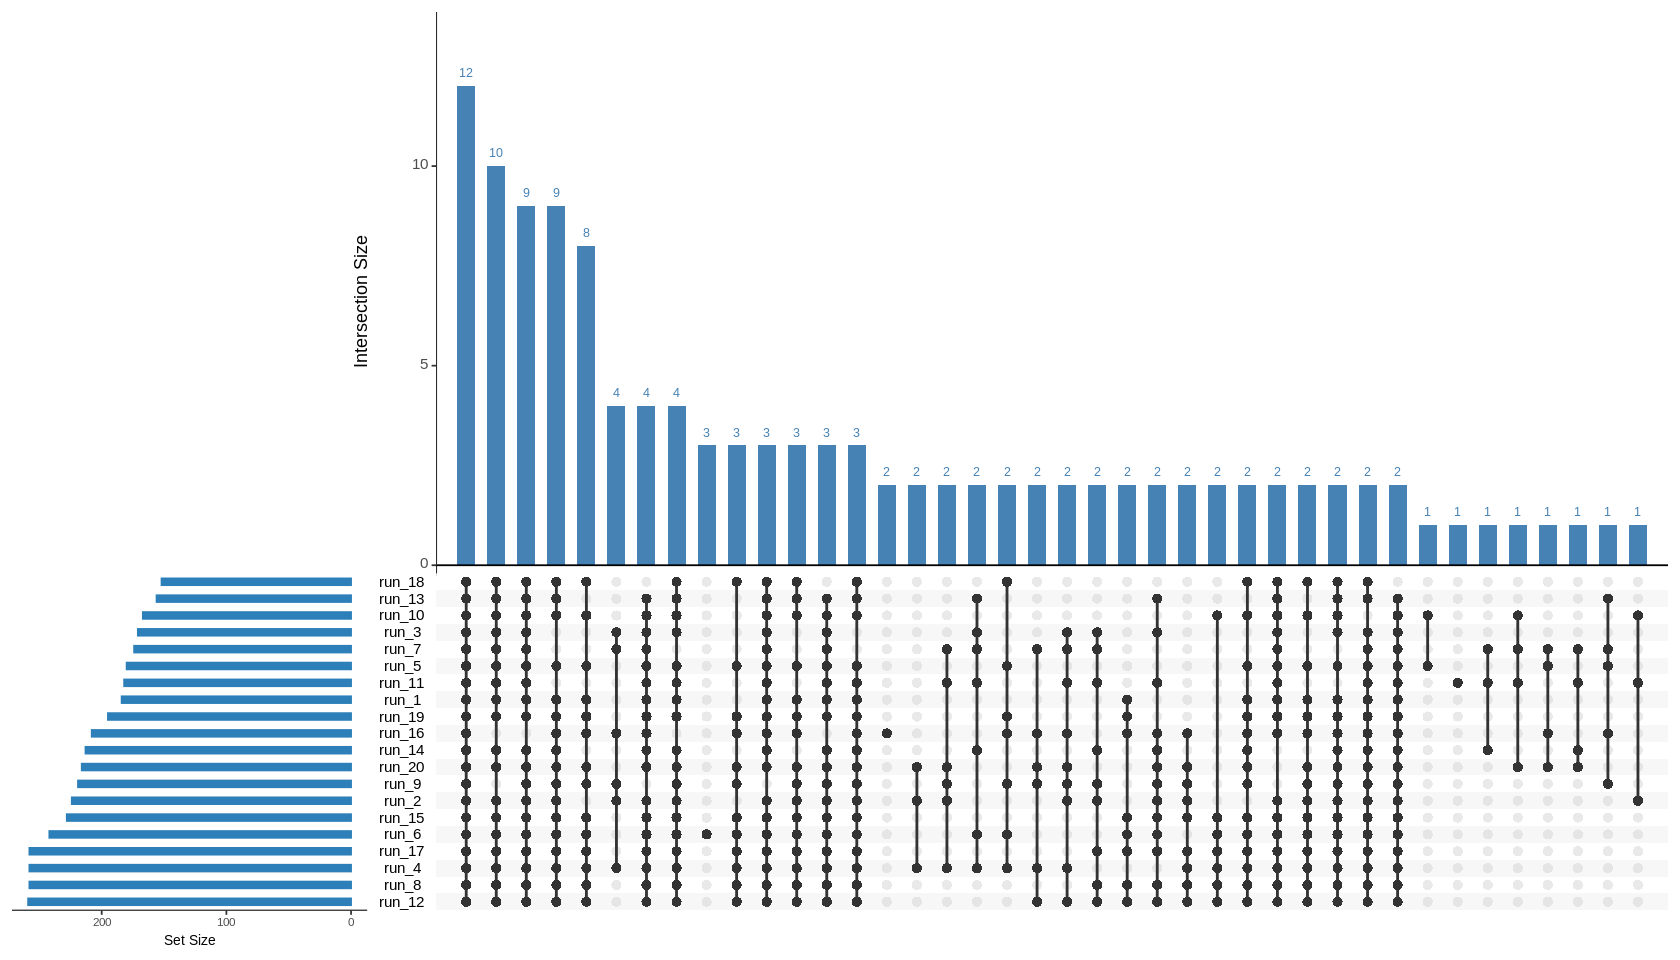

In [ ]:
# Install UpSetR (not in the original package list, needed only for this block)
if (!requireNamespace("UpSetR", quietly = TRUE)) install.packages("UpSetR")
library(UpSetR)

# Convert your existing gene_lists (list of 20 character vectors) into
# UpSetR's expected binary format
upset_data <- fromList(gene_lists)

options(repr.plot.width = 14, repr.plot.height = 8)

upset(
  upset_data,
  nsets = n_runs,                 # show all 20 replicates
  nintersects = 40,                # cap the number of intersections shown, since KVS flagged this plot can get cluttered with 20 sets
  order.by = "freq",                # largest intersections first
  mb.ratio = c(0.6, 0.4),           # relative height: intersection matrix vs. set-size bars
  point.size = 2.5,
  line.size = 0.8,
  text.scale = c(1.3, 1.3, 1, 1, 1.3, 1.2),  # title, axis labels, tick labels, set names, numbers
  main.bar.color = "steelblue",
  sets.bar.color = "#2c7fb8",
  matrix.color = "grey20"
)

## 6. Frequency histogram of gene presence - KVS Block 4 (Plot 2)
*Fix applied: `linestyle` -> `linetype`; threshold generalized from a hardcoded 20-run assumption to `n_runs`.*

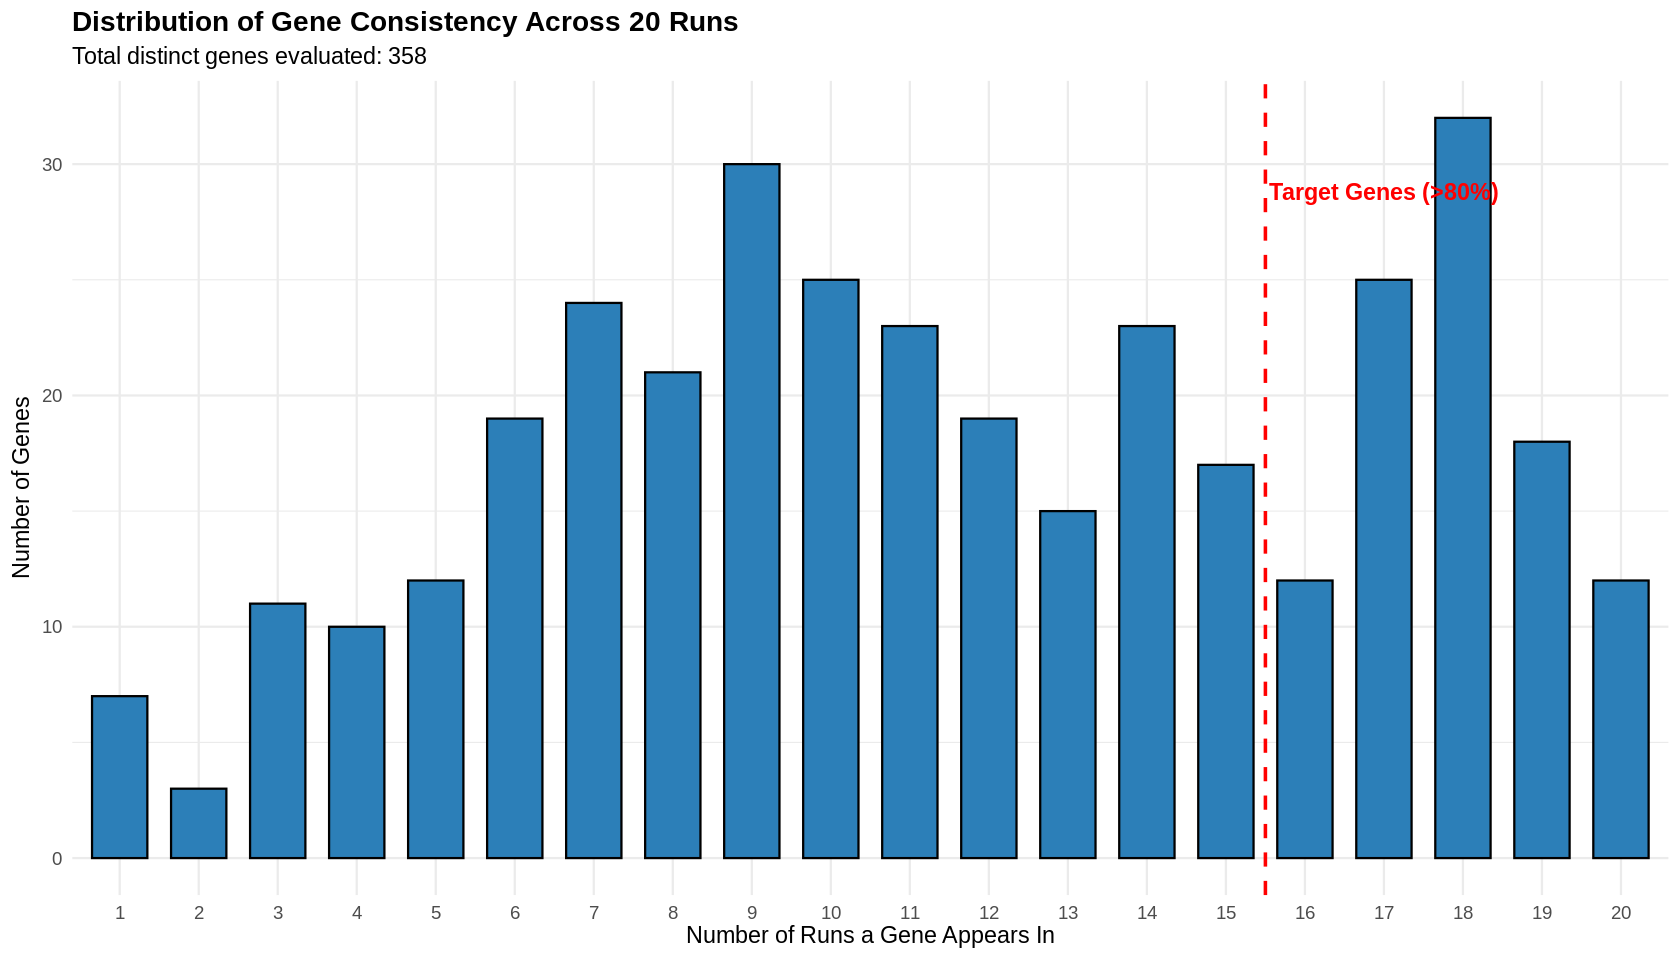

In [ ]:
threshold_count <- ceiling(0.8 * n_runs)

df_freq <- data.frame(Runs = consistency_score)

ggplot(df_freq, aes(x = factor(Runs))) +
  geom_bar(fill = "#2c7fb8", color = "black", width = 0.7) +
  geom_vline(xintercept = threshold_count - 0.5, linetype = "dashed", color = "red", linewidth = 1) +
  annotate("text", x = threshold_count + 1, y = max(table(consistency_score)) * 0.9,
           label = paste0("Target Genes (>", round(100 * threshold_count / n_runs), "%)"),
           color = "red", fontface = "bold") +
  labs(title = paste("Distribution of Gene Consistency Across", n_runs, "Runs"),
       subtitle = paste("Total distinct genes evaluated:", nrow(binary_matrix)),
       x = "Number of Runs a Gene Appears In",
       y = "Number of Genes") +
  theme_minimal(base_size = 14) +
  theme(plot.title = element_text(face = "bold"))

## 7. Jaccard similarity MDS plot - KVS Block 5 (Plot 3)

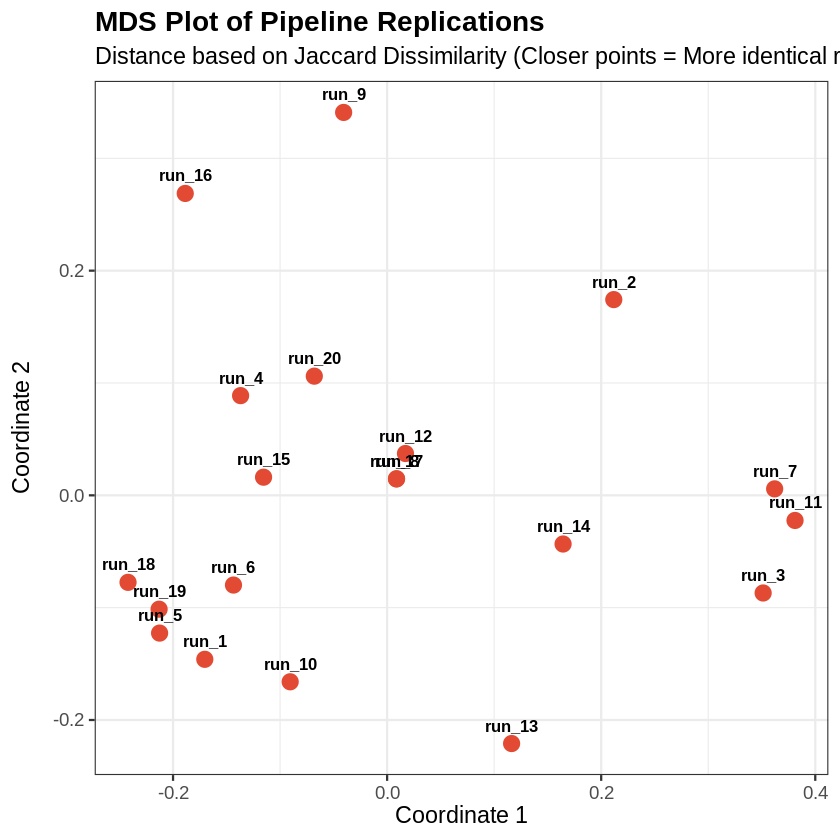

In [ ]:
jaccard_dist <- vegdist(t(binary_matrix), method = "jaccard")

mds_res <- cmdscale(jaccard_dist, eig = TRUE, k = 2)
mds_df <- data.frame(MDS1 = mds_res$points[, 1],
                      MDS2 = mds_res$points[, 2],
                      Run = colnames(binary_matrix))

ggplot(mds_df, aes(x = MDS1, y = MDS2, label = Run)) +
  geom_point(color = "#e34a33", size = 4) +
  geom_text(vjust = -1, size = 3.5, fontface = "bold") +
  labs(title = "MDS Plot of Pipeline Replications",
       subtitle = "Distance based on Jaccard Dissimilarity (Closer points = More identical runs)",
       x = "Coordinate 1",
       y = "Coordinate 2") +
  theme_bw(base_size = 14) +
  theme(plot.title = element_text(face = "bold"))

In [ ]:
jaccard_similarity <- 1 - as.vector(jaccard_dist)

average_jaccard <- mean(jaccard_similarity)
sd_jaccard <- sd(jaccard_similarity)

cat(sprintf("Manuscript Text: The pipeline demonstrated reproducibility across the %d-gene universe boundary, with a mean Jaccard similarity of %.3f (SD = %.3f) across all %d replicated runs.\n",
            n_genes, average_jaccard, sd_jaccard, n_runs))

Manuscript Text: The pipeline demonstrated reproducibility across the 358-gene universe boundary, with a mean Jaccard similarity of 0.508 (SD = 0.119) across all 20 replicated runs.


## 8. Extract the >=80% consistent genes - KVS Block 6

In [ ]:
threshold_count <- ceiling(0.8 * n_runs)
highly_consistent_genes <- names(consistency_score[consistency_score >= threshold_count])

export_df <- data.frame(
  Gene_ID = highly_consistent_genes,
  Runs_Present = consistency_score[highly_consistent_genes],
  Percentage_Presence = (consistency_score[highly_consistent_genes] / n_runs) * 100
)

export_df <- export_df[order(-export_df$Runs_Present), ]

write.csv(export_df, file = "/content/highly_consistent_genes_80pct.csv", row.names = FALSE)

cat("Extraction complete!", nrow(export_df),
    paste0("genes met the >=", round(100 * threshold_count / n_runs), "% threshold. "),
    "Saved to 'highly_consistent_genes_80pct.csv'.\n")

Extraction complete! 99 genes met the >=80% threshold.  Saved to 'highly_consistent_genes_80pct.csv'.


## 9. Gene annotation via biomaRt, with alias/synonym fallback - KVS Block 7
Requires internet access from the Colab runtime. This queries the live Ensembl database, so it may take a minute.

In [ ]:
ensembl <- useEnsembl(biomart = "ensembl", dataset = "hsapiens_gene_ensembl")

tier1_data <- getBM(
  attributes = c("external_gene_name", "description", "gene_biotype"),
  filters = "external_gene_name",
  values = unique_genes,
  mart = ensembl
)

matched_inputs <- tier1_data$external_gene_name
unmatched_inputs <- setdiff(unique_genes, matched_inputs)

tier2_data <- data.frame()
if (length(unmatched_inputs) > 0) {
  cat("Tier 1 missed", length(unmatched_inputs), "genes. Initiating Synonym Fallback...\n")

  synonym_query <- getBM(
    attributes = c("external_synonym", "external_gene_name", "description", "gene_biotype"),
    filters = "external_synonym",
    values = unmatched_inputs,
    mart = ensembl
  )

  if (nrow(synonym_query) > 0) {
    tier2_data <- data.frame(
      external_gene_name = synonym_query$external_synonym,
      description = synonym_query$description,
      gene_biotype = synonym_query$gene_biotype,
      stringsAsFactors = FALSE
    )
    tier2_data <- tier2_data[!duplicated(tier2_data$external_gene_name), ]
  }
}

annot_data_complete <- rbind(tier1_data, tier2_data)
annot_data_complete$description <- gsub(" \\[Source:.*\\]", "", annot_data_complete$description)

threshold_count <- ceiling(0.8 * n_runs)
export_base <- data.frame(
  Gene_Symbol = names(consistency_score[consistency_score >= threshold_count]),
  Runs_Present = consistency_score[consistency_score >= threshold_count],
  Percentage_Presence = (consistency_score[consistency_score >= threshold_count] / n_runs) * 100,
  stringsAsFactors = FALSE
)

final_export_df <- merge(
  x = export_base,
  y = annot_data_complete,
  by.x = "Gene_Symbol",
  by.y = "external_gene_name",
  all.x = TRUE
)

final_export_df$description[is.na(final_export_df$description)] <- "Unmapped Symbol / No entry found"
final_export_df$gene_biotype[is.na(final_export_df$gene_biotype)] <- "Unknown"

final_export_df <- final_export_df[order(-final_export_df$Runs_Present), ]
write.csv(final_export_df, file = "/content/highly_consistent_fallback_annotated_genes.csv", row.names = FALSE)

cat("Success! Generated spreadsheet with", nrow(final_export_df), "annotated target genes.\n")

Tier 1 missed 1 genes. Initiating Synonym Fallback...
Success! Generated spreadsheet with 99 annotated target genes.


## 10. SMC & MCC similarity matrices + boundary-aware MDS - KVS Block 8
This is her fix for the "shared negatives should count" issue with plain Jaccard.

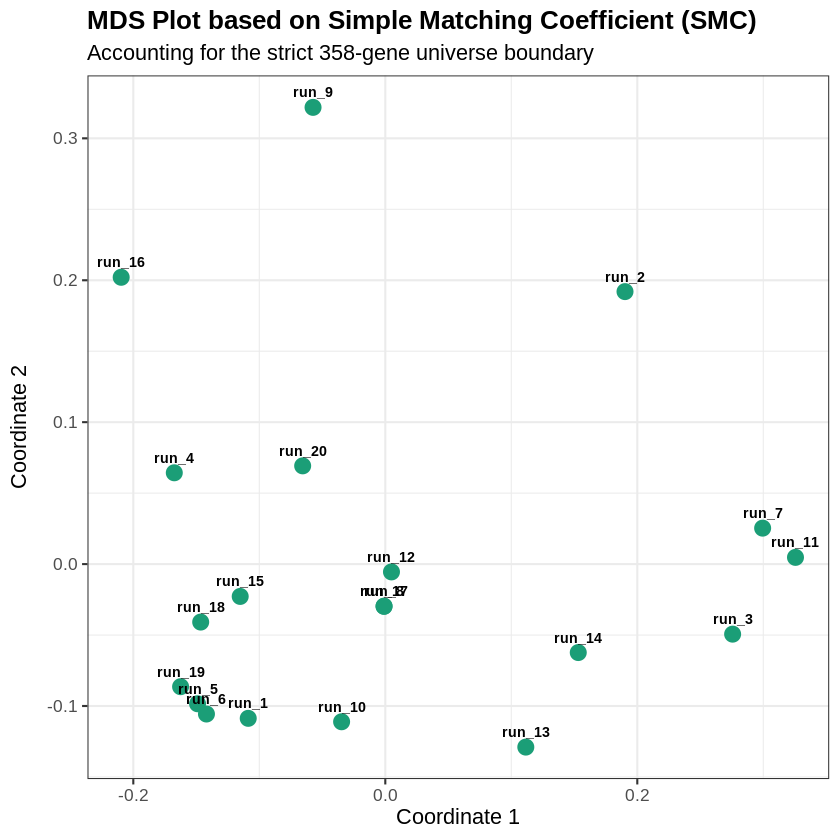

In [ ]:
n_runs_col <- ncol(binary_matrix)
n_genes <- nrow(binary_matrix)

smc_matrix <- matrix(1, nrow = n_runs_col, ncol = n_runs_col,
                      dimnames = list(colnames(binary_matrix), colnames(binary_matrix)))
mcc_matrix <- matrix(1, nrow = n_runs_col, ncol = n_runs_col,
                      dimnames = list(colnames(binary_matrix), colnames(binary_matrix)))

for (i in 1:(n_runs_col - 1)) {
  for (j in (i + 1):n_runs_col) {
    vec1 <- binary_matrix[, i]
    vec2 <- binary_matrix[, j]

    TP <- sum(vec1 == 1 & vec2 == 1)
    TN <- sum(vec1 == 0 & vec2 == 0)
    FP <- sum(vec1 == 0 & vec2 == 1)
    FN <- sum(vec1 == 1 & vec2 == 0)

    SMC <- (TP + TN) / n_genes
    smc_matrix[i, j] <- SMC
    smc_matrix[j, i] <- SMC

    num <- (TP * TN) - (FP * FN)
    den <- sqrt(as.numeric(TP + FP) * as.numeric(TP + FN) * as.numeric(TN + FP) * as.numeric(TN + FN))
    MCC <- if (den == 0) 0 else num / den
    mcc_matrix[i, j] <- MCC
    mcc_matrix[j, i] <- MCC
  }
}

plot_pipeline_mds <- function(sim_matrix, metric_name) {
  dist_matrix <- as.dist(1 - sim_matrix)
  mds_res <- cmdscale(dist_matrix, k = 2)
  mds_df <- data.frame(MDS1 = mds_res[, 1], MDS2 = mds_res[, 2], Run = rownames(mds_res))

  ggplot(mds_df, aes(x = MDS1, y = MDS2, label = Run)) +
    geom_point(color = "#1b9e77", size = 4) +
    geom_text(vjust = -1, size = 3, fontface = "bold") +
    labs(title = paste("MDS Plot based on", metric_name),
         subtitle = paste0("Accounting for the strict ", n_genes, "-gene universe boundary"),
         x = "Coordinate 1", y = "Coordinate 2") +
    theme_bw(base_size = 13) +
    theme(plot.title = element_text(face = "bold"))
}

plot_smc <- plot_pipeline_mds(smc_matrix, "Simple Matching Coefficient (SMC)")
plot_mcc <- plot_pipeline_mds(mcc_matrix, "Matthews Correlation Coefficient (MCC)")

print(plot_smc)

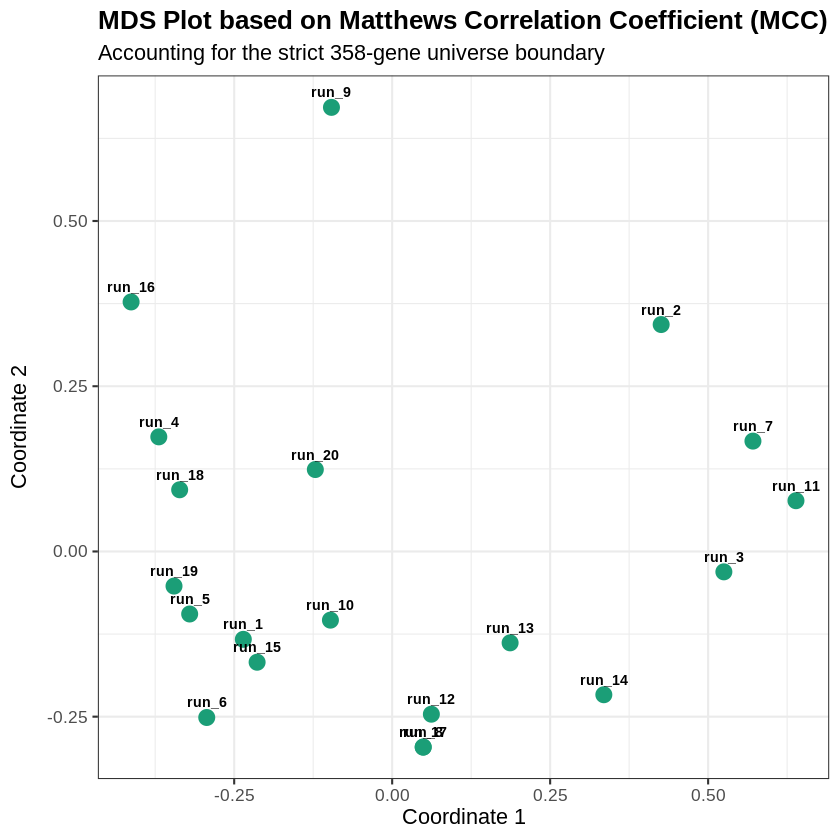

In [ ]:
# Also view the MCC-based plot
print(plot_mcc)

## 11. Reproducibility baseline (mean SMC) & outlier dendrogram - KVS Block 9

In [ ]:
unique_pairwise_smc <- smc_matrix[lower.tri(smc_matrix)]

average_smc <- mean(unique_pairwise_smc)
sd_smc <- sd(unique_pairwise_smc)

cat(sprintf("Manuscript Text: The pipeline demonstrated high reproducibility across the %d-gene universe boundary, with a mean Simple Matching Coefficient (SMC) of %.3f (SD = %.3f) across all %d replicated runs.\n",
            n_genes, average_smc, sd_smc, n_runs))

Manuscript Text: The pipeline demonstrated high reproducibility across the 358-gene universe boundary, with a mean Simple Matching Coefficient (SMC) of 0.620 (SD = 0.103) across all 20 replicated runs.


In [ ]:
unique_pairwise_mcc <- mcc_matrix[lower.tri(mcc_matrix)]

average_mcc <- mean(unique_pairwise_mcc)
sd_mcc <- sd(unique_pairwise_mcc)

cat(sprintf("Manuscript Text: The pipeline demonstrated reproducibility across the %d-gene universe boundary, with a mean Matthews Correlation Coefficient (MCC) of %.3f (SD = %.3f) across all %d replicated runs.\n",
            n_genes, average_mcc, sd_mcc, n_runs))

Manuscript Text: The pipeline demonstrated reproducibility across the 358-gene universe boundary, with a mean Matthews Correlation Coefficient (MCC) of 0.235 (SD = 0.211) across all 20 replicated runs.


In [ ]:
###whether to choose SMC or MCC depends how the genes are distributed among these 20 runs
colSums(binary_matrix)

run_1 run_10 run_11 run_12 run_13 run_14 run_15 run_16 run_17 run_18 run_19 
   184    167    182    259    156    213    228    208    258    152    195 
 run_2 run_20  run_3  run_4  run_5  run_6  run_7  run_8  run_9 
   224    216    171    258    180    242    174    258    219

Outlier Detection: No individual runs were identified as statistical outliers.
Outlier Detection Result:
Outlier Detection: No individual runs were identified as statistical outliers.


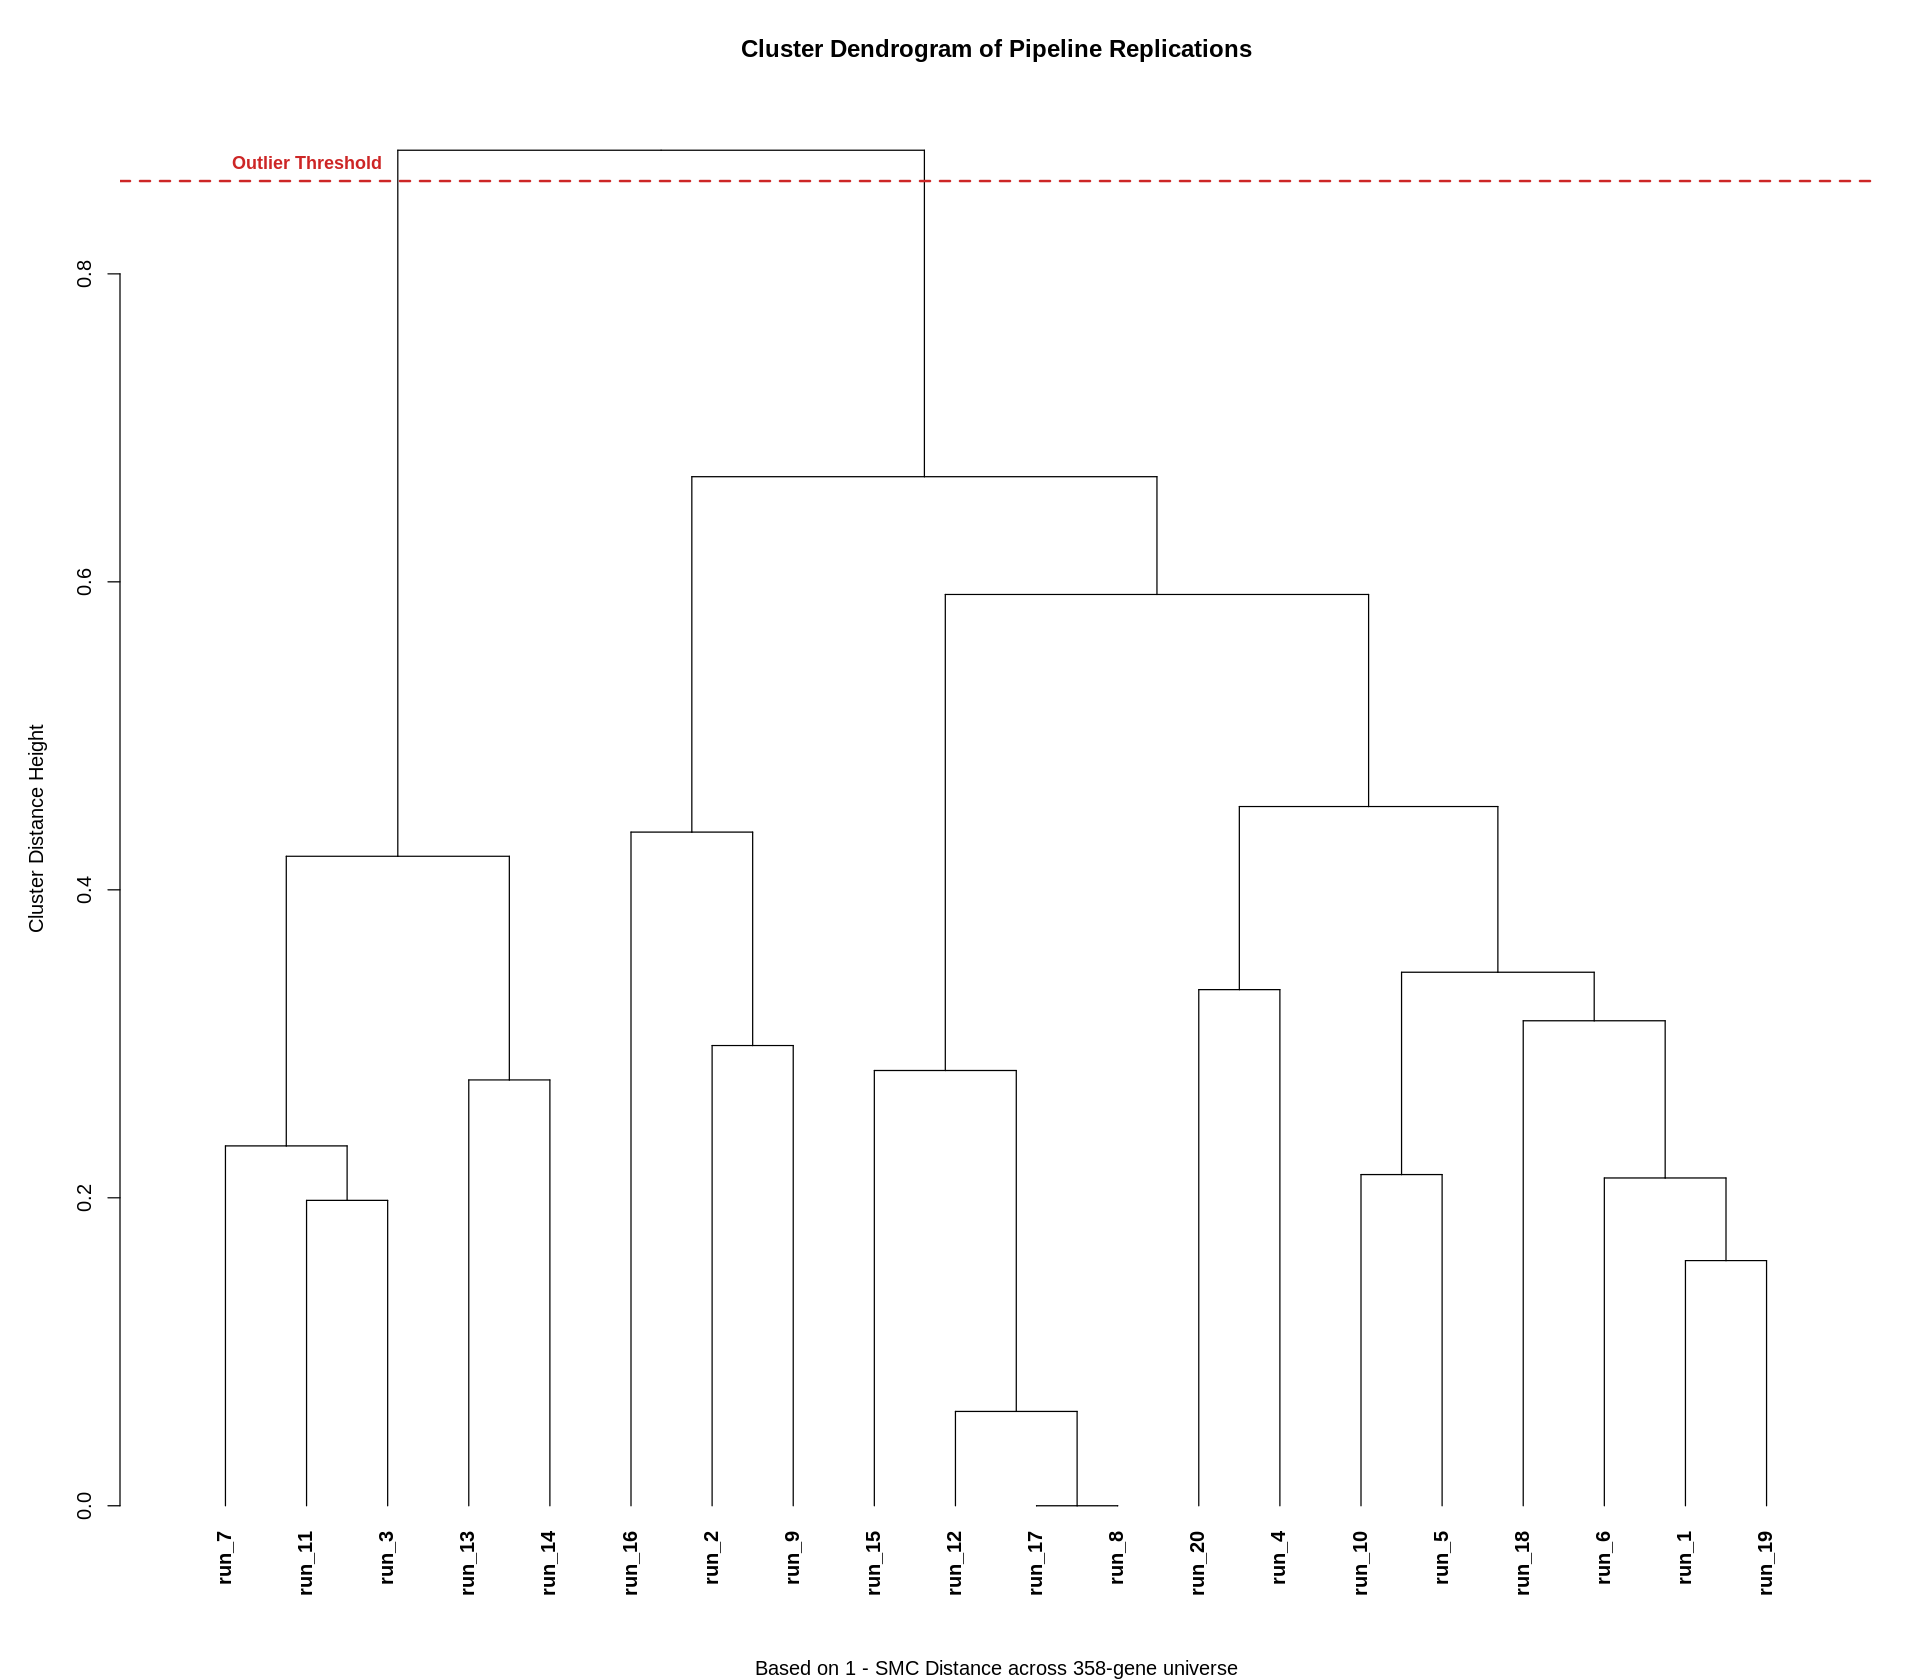

In [ ]:
smc_distance <- as.dist(1 - smc_matrix)
hc_res <- hclust(smc_distance, method = "ward.D2")

all_heights <- hc_res$height
outlier_cutoff <- mean(all_heights) + (2.5 * sd(all_heights))

clusters <- cutree(hc_res, h = outlier_cutoff)
cluster_counts <- table(clusters)
outlier_clusters <- names(cluster_counts[cluster_counts == 1])
outlier_runs <- names(clusters[clusters %in% outlier_clusters])

par(mar = c(5, 5, 4, 2))
plot(as.dendrogram(hc_res),
     main = "Cluster Dendrogram of Pipeline Replications",
     sub = paste0("Based on 1 - SMC Distance across ", n_genes, "-gene universe"),
     ylab = "Cluster Distance Height",
     nodePar = list(lab.cex = 1.0, lab.font = 2, pch = NA))

abline(h = outlier_cutoff, col = "firebrick3", lty = "dashed", lwd = 2)
text(x = 2, y = outlier_cutoff, labels = "Outlier Threshold",
     col = "firebrick3", pos = 3, font = 2, cex = 0.9)

if (length(outlier_runs) > 0) {
  cat("Outlier Detection Alert: The following run(s) crossed the statistical distance threshold:\n")
  print(outlier_runs)
} else {
  cat("Outlier Detection: No individual runs were identified as statistical outliers.\n")
}

cat("Outlier Detection Result:\n")
if (length(outlier_runs) > 0) {
  cat("Outlier Detection Alert: The following run(s) crossed the statistical distance threshold:\n")
  print(outlier_runs)
} else {
  cat("Outlier Detection: No individual runs were identified as statistical outliers.\n")
}

## 12. Global density scatter - KVS Block 10
*Adapted to use your real `hotzone_cluster_stats.csv` per run (mean edge variance, Fiedler value, cluster size) instead of her mock data. Fix applied: `color = ..black..` (invalid ggplot2 syntax) -> `color = "black"`.*

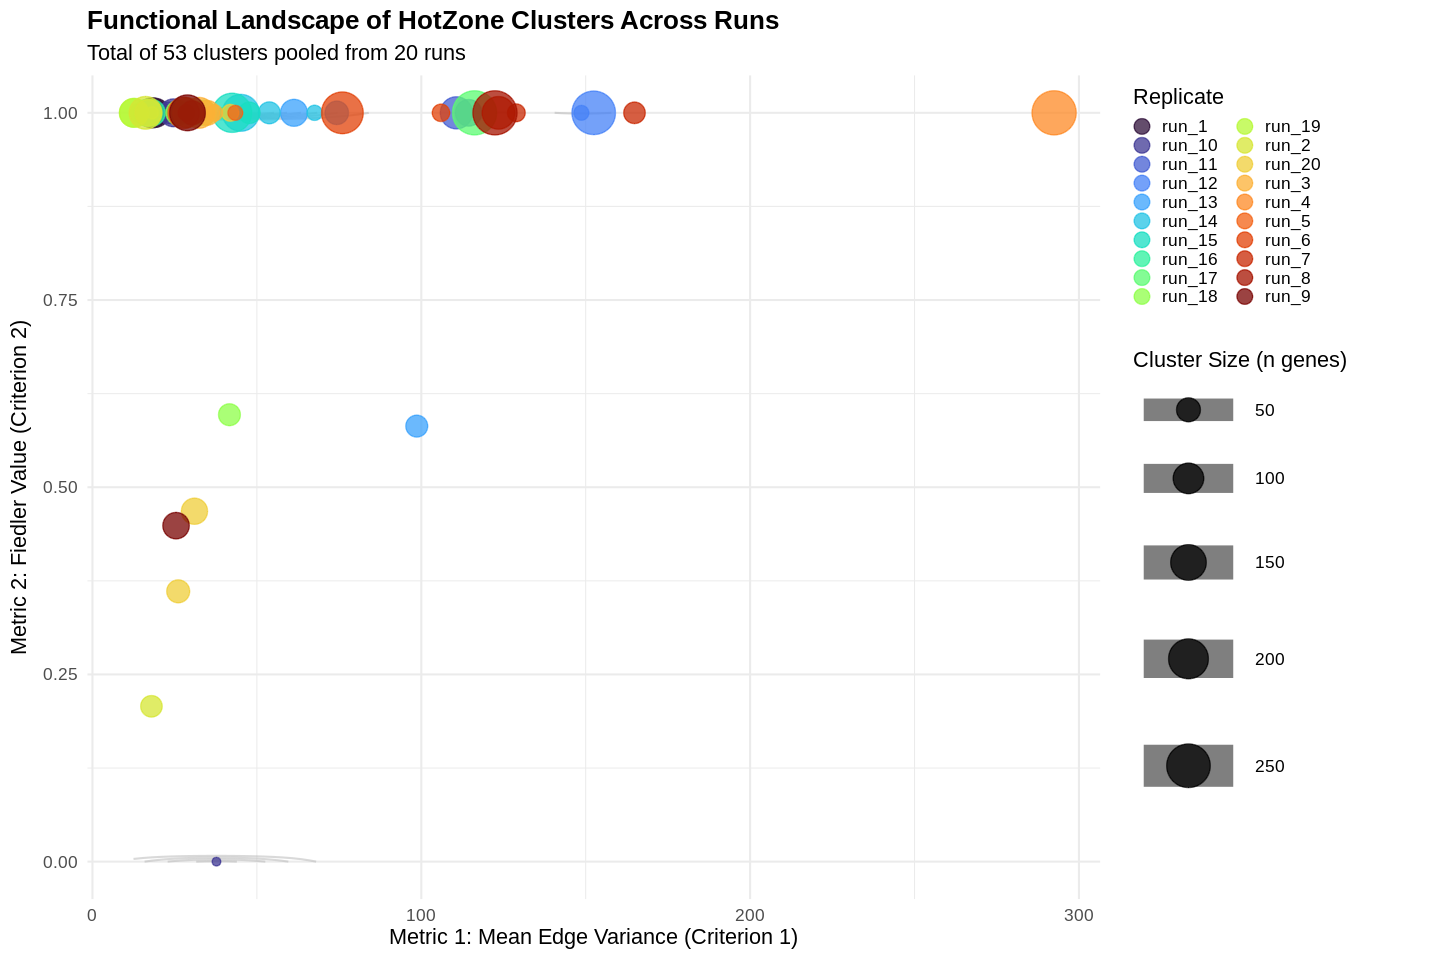

In [ ]:
all_clusters_list <- list()

for (run_name in names(cluster_stats_list)) {
  stats_df <- cluster_stats_list[[run_name]]
  all_clusters_list[[run_name]] <- data.frame(
    Replicate = run_name,
    Cluster_Num = paste0("C", stats_df$cluster),
    Metric1 = stats_df$mean_edge_variance,
    Metric2 = stats_df$fiedler_value,
    Metric3 = stats_df$n_genes
  )
}

all_clusters_df <- do.call(rbind, all_clusters_list)

options(repr.plot.width = 12, repr.plot.height = 8)

ggplot(all_clusters_df, aes(x = Metric1, y = Metric2)) +
  geom_density_2d(color = "grey70", alpha = 0.5) +
  geom_point(aes(size = Metric3, color = Replicate), alpha = 0.75) +
  scale_size_continuous(range = c(2, 12), guide = guide_legend(override.aes = list(color = "black"))) +
  scale_color_viridis_d(option = "turbo", guide = guide_legend(ncol = 2, override.aes = list(size = 4))) +
  labs(title = "Functional Landscape of HotZone Clusters Across Runs",
       subtitle = paste("Total of", nrow(all_clusters_df), "clusters pooled from", n_runs, "runs"),
       x = "Metric 1: Mean Edge Variance (Criterion 1)",
       y = "Metric 2: Fiedler Value (Criterion 2)",
       size = "Cluster Size (n genes)",
       color = "Replicate") +
  theme_minimal(base_size = 13) +
  theme(plot.title = element_text(face = "bold"),
        legend.position = "right",
        legend.justification = "top",
        legend.box = "vertical",
        legend.key.size = unit(0.4, "cm"))

In [ ]:
###Differential analysis

In [1]:
# -------------------------------------------------------------
# Load the four exported objects from PipelineHot.ipynb
# -------------------------------------------------------------
edge_matrix <- read.csv("edge_matrix.csv", row.names = 1)
edge_matrix <- as.matrix(edge_matrix)

edges_df <- read.csv("edges_df.csv", stringsAsFactors = FALSE)

hotzone_genes <- read.csv("hotzone_genes.csv", stringsAsFactors = FALSE)$gene

cluster_labels_df <- read.csv("cluster_labels_hot_11.csv", stringsAsFactors = FALSE)
cluster_labels <- setNames(as.character(cluster_labels_df$cluster), cluster_labels_df[[1]])

# -------------------------------------------------------------
# 1) Build an edge-by-patient matrix
# -------------------------------------------------------------
cluster_labels <- cluster_labels[colnames(edge_matrix)]

# -------------------------------------------------------------
# 2) Restrict to pooled HotZone genes  ← ADD THE FILTERING STEP HERE
# -------------------------------------------------------------
hotzone_edges <- edges_df[
  edges_df$gene1 %in% hotzone_genes & edges_df$gene2 %in% hotzone_genes,
]

edge_ids <- paste(hotzone_edges$gene1, hotzone_edges$gene2, sep = "__")
edge_matrix_hz <- edge_matrix[edge_ids, ]

# -------------------------------------------------------------
# 3) Compute average ISN per patient cluster
# -------------------------------------------------------------
cluster_means <- sapply(unique(cluster_labels), function(cl) {
  rowMeans(edge_matrix_hz[, cluster_labels == cl, drop = FALSE], na.rm = TRUE)
})
cluster_means <- as.data.frame(cluster_means)

In [2]:
cat("Full network edges:", nrow(edge_matrix), "\n")
cat("HotZone-restricted edges:", nrow(edge_matrix_hz), "\n")

Full network edges: 128881 
HotZone-restricted edges: 18225 


In [3]:
compare_clusters <- function(edge_matrix, cluster_labels, c1, c2) {
  x1 <- edge_matrix[, cluster_labels == c1, drop = FALSE]
  x2 <- edge_matrix[, cluster_labels == c2, drop = FALSE]
  mean1 <- rowMeans(x1, na.rm = TRUE)
  mean2 <- rowMeans(x2, na.rm = TRUE)
  delta <- mean1 - mean2
  pval <- apply(edge_matrix, 1, function(e) {
    wilcox.test(e[cluster_labels == c1], e[cluster_labels == c2])$p.value
  })
  data.frame(edge = rownames(edge_matrix), cluster1 = c1, cluster2 = c2,
             mean_cluster1 = mean1, mean_cluster2 = mean2, delta = delta,
             abs_delta = abs(delta), p_value = pval,
             FDR = p.adjust(pval, method = "BH"))
}

singleton_vs_rest <- function(edge_matrix, cluster_labels, cl) {
  in_cl <- cluster_labels == cl
  mean_cl <- rowMeans(edge_matrix[, in_cl, drop = FALSE], na.rm = TRUE)
  mean_rest <- rowMeans(edge_matrix[, !in_cl, drop = FALSE], na.rm = TRUE)
  data.frame(edge = rownames(edge_matrix), cluster = cl, mean_cluster = mean_cl,
             mean_rest = mean_rest, delta_vs_rest = mean_cl - mean_rest,
             abs_delta = abs(mean_cl - mean_rest))[order(-abs(mean_cl - mean_rest)), ]
}

compare_edge_variance <- function(edge_matrix, cluster_labels, c1, c2) {
  x1 <- edge_matrix[, cluster_labels == c1, drop = FALSE]
  x2 <- edge_matrix[, cluster_labels == c2, drop = FALSE]
  out <- lapply(seq_len(nrow(edge_matrix)), function(i) {
    v1 <- as.numeric(x1[i, ]); v2 <- as.numeric(x2[i, ])
    if (length(v1) < 3 || length(v2) < 3) {
      return(data.frame(edge = rownames(edge_matrix)[i], var_c1 = var(v1, na.rm = TRUE),
                         var_c2 = var(v2, na.rm = TRUE),
                         log2_var_ratio = log2((var(v1, na.rm = TRUE) + 1e-8) / (var(v2, na.rm = TRUE) + 1e-8)),
                         p_value = NA))
    }
    test <- var.test(v1, v2)
    data.frame(edge = rownames(edge_matrix)[i], var_c1 = var(v1, na.rm = TRUE),
               var_c2 = var(v2, na.rm = TRUE),
               log2_var_ratio = log2((var(v1, na.rm = TRUE) + 1e-8) / (var(v2, na.rm = TRUE) + 1e-8)),
               p_value = test$p.value)
  })
  res <- do.call(rbind, out)
  res$FDR <- p.adjust(res$p_value, method = "BH")
  res[order(-abs(res$log2_var_ratio)), ]
}

perm_variance_test <- function(edge_matrix, cluster_labels, c1, c2, B = 1000) {
  keep <- cluster_labels %in% c(c1, c2)
  mat <- edge_matrix[, keep, drop = FALSE]
  labs <- cluster_labels[keep]
  observed <- apply(mat, 1, function(x) {
    log2((var(x[labs == c1], na.rm = TRUE) + 1e-8) / (var(x[labs == c2], na.rm = TRUE) + 1e-8))
  })
  perm <- replicate(B, {
    labs_perm <- sample(labs)
    apply(mat, 1, function(x) {
      log2((var(x[labs_perm == c1], na.rm = TRUE) + 1e-8) / (var(x[labs_perm == c2], na.rm = TRUE) + 1e-8))
    })
  })
  pval <- sapply(seq_along(observed), function(i) mean(abs(perm[i, ]) >= abs(observed[i])))
  data.frame(edge = rownames(mat), log2_var_ratio = observed, p_value = pval,
             FDR = p.adjust(pval, "BH"))[order(-abs(observed)), ]
}

In [4]:
cluster_sizes <- table(cluster_labels)
print(cluster_sizes)

cat("\nTotal clusters:", length(cluster_sizes), "\n")
cat("Total patients:", sum(cluster_sizes), "\n\n")

singleton_threshold <- 2

singleton_clusters <- names(cluster_sizes[cluster_sizes < singleton_threshold])
sufficient_clusters <- names(cluster_sizes[cluster_sizes >= singleton_threshold])

cat("Clusters flagged as singleton/unstable (n <", singleton_threshold, "):\n")
print(singleton_clusters)

cat("\nClusters with sufficient sample size for formal pairwise testing:\n")
print(sufficient_clusters)

sorted_sufficient <- sort(cluster_sizes[sufficient_clusters], decreasing = TRUE)
cat("\nSufficient clusters ranked by size (largest first):\n")
print(sorted_sufficient)

if (length(sorted_sufficient) >= 2) {
  c1 <- names(sorted_sufficient)[1]
  c2 <- names(sorted_sufficient)[2]
  cat("\nSuggested pairwise comparison: cluster", c1, "vs cluster", c2,
      "(", sorted_sufficient[1], "vs", sorted_sufficient[2], "patients )\n")
} else {
  cat("\nWarning: fewer than 2 clusters have sufficient sample size for a formal pairwise comparison.\n")
}

cluster_labels
 0  1 10  2  3  4  5  6  7  8  9 
 2  3  3  4  5  8 18  2  1  3  1 

Total clusters: 11 
Total patients: 50 

Clusters flagged as singleton/unstable (n < 2 ):
[1] "7" "9"

Clusters with sufficient sample size for formal pairwise testing:
[1] "0"  "1"  "10" "2"  "3"  "4"  "5"  "6"  "8" 

Sufficient clusters ranked by size (largest first):
cluster_labels
 5  4  3  2  1 10  8  0  6 
18  8  5  4  3  3  3  2  2 

Suggested pairwise comparison: cluster 5 vs cluster 4 ( 18 vs 8 patients )


In [5]:
cat("cluster_labels exists:", exists("cluster_labels"), "\n")
cat("edge_matrix_hz exists:", exists("edge_matrix_hz"), "\n")
cat("compare_edge_variance exists:", exists("compare_edge_variance"), "\n")
cat("c1 exists:", exists("c1"), "\n")
cat("c2 exists:", exists("c2"), "\n")
cat("singleton_clusters exists:", exists("singleton_clusters"), "\n")

cluster_labels exists: TRUE 
edge_matrix_hz exists: TRUE 
compare_edge_variance exists: TRUE 
c1 exists: TRUE 
c2 exists: TRUE 
singleton_clusters exists: TRUE 


In [6]:
# Run the comparisons between your two main clusters
res_mean <- compare_clusters(edge_matrix_hz, cluster_labels, c1, c2)
res_var  <- compare_edge_variance(edge_matrix_hz, cluster_labels, c1, c2)
res_perm <- perm_variance_test(edge_matrix_hz, cluster_labels, c1, c2, B = 1000)

# Run the descriptive comparison for each singleton cluster
singleton_results <- lapply(singleton_clusters, function(cl) {
  singleton_vs_rest(edge_matrix_hz, cluster_labels, cl)
})
names(singleton_results) <- singleton_clusters

# Save everything to disk immediately
write.csv(res_mean, "res_mean.csv", row.names = FALSE)
write.csv(res_var, "res_var.csv", row.names = FALSE)
write.csv(res_perm, "res_perm.csv", row.names = FALSE)

for (cl in singleton_clusters) {
  write.csv(singleton_results[[cl]], paste0("singleton_", cl, "_vs_rest.csv"), row.names = FALSE)
}

cat("Saved: res_mean.csv, res_var.csv, res_perm.csv\n")
cat("Saved singleton comparisons for clusters:", paste(singleton_clusters, collapse = ", "), "\n")

Saved: res_mean.csv, res_var.csv, res_perm.csv
Saved singleton comparisons for clusters: 7, 9 


In [7]:
exists("cluster_labels")

[1] TRUE

In [10]:
install.packages("BiocManager")

if (!requireNamespace("clusterProfiler", quietly = TRUE)) BiocManager::install("clusterProfiler")
if (!requireNamespace("org.Hs.eg.db", quietly = TRUE)) BiocManager::install("org.Hs.eg.db")
if (!requireNamespace("ReactomePA", quietly = TRUE)) BiocManager::install("ReactomePA")

library(clusterProfiler)
library(org.Hs.eg.db)
library(ReactomePA)

ego <- enrichGO(
  gene = top_genes,
  OrgDb = org.Hs.eg.db,
  keyType = "SYMBOL",
  ont = "BP",
  pAdjustMethod = "BH"
)

react <- enrichPathway(
  gene = top_genes,
  organism = "human",
  pAdjustMethod = "BH"
)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

'getOption("repos")' replaces Bioconductor standard repositories, see
'help("repositories", package = "BiocManager")' for details.
Replacement repositories:
    CRAN: https://cran.rstudio.com

Bioconductor version 3.23 (BiocManager 1.30.27), R 4.6.0 (2026-04-24)

Installing package(s) 'BiocVersion', 'clusterProfiler'

also installing the dependencies ‘fontBitstreamVera’, ‘fontLiberation’, ‘fontquiver’, ‘XVector’, ‘Seqinfo’, ‘gridGraphics’, ‘gdtools’, ‘lazyeval’, ‘tweenr’, ‘polyclip’, ‘png’, ‘Biostrings’, ‘ggplotify’, ‘patchwork’, ‘ape’, ‘ggiraph’, ‘tidytree’, ‘treeio’, ‘ggforce’, ‘BiocGenerics’, ‘Biobase’, ‘IRanges’, ‘RSQLite’, ‘S4Vectors’, ‘KEGGREST’, ‘RcppEigen’, ‘aplot’, ‘DOSE’, ‘ggfun’, ‘ggnewscale’, ‘ggrepel’, ‘ggtangle’, ‘ggtree’, ‘reshape2’, ‘scatterpie’, ‘tidydr’, ‘aisdk’, ‘AnnotationDbi’, ‘enrichit’, ‘enrichplot’, ‘GO.db’, ‘GOSemSim’, ‘gson’, ‘igraph’, ‘plyr’, ‘qvalue’, ‘yulab.utils’


Old packa

In [11]:
# 1) Check what's actually in top_genes
print(top_genes)
length(top_genes)
sum(is.na(top_genes))

# 2) Test how many of these genes org.Hs.eg.db actually recognizes
library(org.Hs.eg.db)
mapped <- select(org.Hs.eg.db, keys = top_genes, keytype = "SYMBOL", columns = "ENTREZID")
print(mapped)
cat("Genes successfully mapped:", sum(!is.na(mapped$ENTREZID)), "out of", length(top_genes), "\n")

 [1] "TFE3"     "AFF2"     "ZMAT1"    "SLC38A5"  "RAI2"     "RAB41"   
 [7] "ZC3H12B"  "CSAG1"    "GAGE12H"  "PIGA"     "NLGN4Y"   "RPS4Y1"  
[13] "PCDH19"   "HMGB3"    "SLC25A5"  "RBMY1D"   "CNKSR2"   "BEX5"    
[19] "BTK"      "NLGN3"    "GAGE12B"  "CHIC1"    "MORF4L2"  "ZXDA"    
[25] "FRMPD4"   "BCOR"     "SLC25A14" "AP1S2"    "TMSB15A"  "CLCN5"   
[31] "ZNF630"   "ZFY"      "SLC6A8"   "BEND2"    "TBL1X"    "NUDT10"  
[37] "RBM10"    "RAP2C"    "RPS4X"    "PFKFB1"   "PJA1"     "FAM47C"  
[43] "TMSB4X"   "SLC25A43" "FTHL17"   "PGK1"     "GPM6B"    "TAF9B"   
[49] "MAOB"     "CXorf38"  "HS6ST2"   "ZNF81"    "SH3BGRL"  "PAGE2B"  
[55] "GAGE12D"  "AIFM1"    "NDUFB11"  "TAF7L"    "ARHGAP4"  "PIM2"    
[61] "SCML1"    "ARHGEF9"  "CITED1"   "CDK16"    "PDZD11"   "MAGEC3"  
[67] "IRAK1"    "GABRQ"    "UBQLN2"   "GRIA3"    "MAMLD1"   "MAP3K15" 
[73] "NAP1L3"   "CSTF2"    "MSL3"     "MBNL3"    "KDM6A"    "ARSD"    
[79] "TSPY1"    "DYNLT3"   "LONRF3"   "UTY"      "GAGE12G"  "PAK3"    
[85] "

[1] 99

[1] 0

'select()' returned 1:1 mapping between keys and columns



     SYMBOL  ENTREZID
1      TFE3      7030
2      AFF2      2334
3     ZMAT1     84460
4   SLC38A5     92745
5      RAI2     10742
6     RAB41    347517
7   ZC3H12B    340554
8     CSAG1    158511
9   GAGE12H    729442
10     PIGA      5277
11   NLGN4Y     22829
12   RPS4Y1      6192
13   PCDH19     57526
14    HMGB3      3149
15  SLC25A5       292
16   RBMY1D    378949
17   CNKSR2     22866
18     BEX5    340542
19      BTK       695
20    NLGN3     54413
21  GAGE12B    729428
22    CHIC1     53344
23  MORF4L2      9643
24     ZXDA      7789
25   FRMPD4      9758
26     BCOR     54880
27 SLC25A14      9016
28    AP1S2      8905
29  TMSB15A     11013
30    CLCN5      1184
31   ZNF630     57232
32      ZFY      7544
33   SLC6A8      6535
34    BEND2    139105
35    TBL1X      6907
36   NUDT10    170685
37    RBM10      8241
38    RAP2C     57826
39    RPS4X      6191
40   PFKFB1      5207
41     PJA1     64219
42   FAM47C    442444
43   TMSB4X      7114
44 SLC25A43    203427
45   FTHL1

In [12]:
## new line
res <- compare_edge_variance(edge_matrix_hz, cluster_labels, c1, c2)

top_edges <- head(res, 100)
top_genes <- unique(unlist(strsplit(top_edges$edge, "__")))

# -------------------------------------------------------------
# 8) Convert top differential edges to genes
#    NOTE: 'res' here must be the output of compare_edge_variance()
#    or perm_variance_test() (or compare_clusters()) for a specific
#    c1/c2 pair — run one of those first and assign it to res.
# -------------------------------------------------------------
# -------------------------------------------------------------
# 9) Run GO and Reactome enrichment on those genes
# -------------------------------------------------------------
if (!requireNamespace("clusterProfiler", quietly = TRUE)) BiocManager::install("clusterProfiler")
if (!requireNamespace("org.Hs.eg.db", quietly = TRUE)) BiocManager::install("org.Hs.eg.db")
if (!requireNamespace("ReactomePA", quietly = TRUE)) BiocManager::install("ReactomePA")

library(clusterProfiler)
library(org.Hs.eg.db)
library(ReactomePA)

# GO enrichment (SYMBOL keytype works directly here)
ego_raw <- enrichGO(
  gene = top_genes,
  OrgDb = org.Hs.eg.db,
  keyType = "SYMBOL",
  ont = "BP",
  pAdjustMethod = "BH",
  pvalueCutoff = 1,
  qvalueCutoff = 1
)

# Reactome enrichment requires Entrez IDs, not symbols — map first
mapped <- select(org.Hs.eg.db, keys = top_genes, keytype = "SYMBOL", columns = "ENTREZID")
entrez_ids <- na.omit(mapped$ENTREZID)
entrez_ids <- as.character(entrez_ids)

react_raw <- enrichPathway(
  gene = entrez_ids,
  organism = "human",
  pAdjustMethod = "BH",
  pvalueCutoff = 1,
  qvalueCutoff = 1,
  readable = TRUE  # converts Entrez IDs back to gene symbols in the output
)

cat("GO terms (unfiltered):", nrow(as.data.frame(ego_raw)), "\n")
cat("Reactome pathways (unfiltered):", nrow(as.data.frame(react_raw)), "\n")

head(as.data.frame(ego_raw)[, c("Description", "pvalue", "p.adjust", "qvalue")])
head(as.data.frame(react_raw)[, c("Description", "pvalue", "p.adjust", "qvalue")])

# -------------------------------------------------------------
# Save everything — using the correct object names
# -------------------------------------------------------------
ego_df <- as.data.frame(ego_raw)
react_df <- as.data.frame(react_raw)

write.csv(ego_df, "go_enrichment_results.csv", row.names = FALSE)
write.csv(react_df, "reactome_enrichment_results.csv", row.names = FALSE)

saveRDS(ego_raw, "ego_object.rds")
saveRDS(react_raw, "react_object.rds")

cat("GO enrichment terms found:", nrow(ego_df), "\n")
cat("Reactome pathways found:", nrow(react_df), "\n")

res_perm_sorted <- res_perm[order(-abs(res_perm$log2_var_ratio)), ]
top_edges_perm <- head(res_perm_sorted, 100)
top_genes_perm <- unique(unlist(strsplit(top_edges_perm$edge, "__")))

# Re-run the same GO/Reactome enrichment on this alternate gene list
ego_perm <- enrichGO(gene = top_genes_perm, OrgDb = org.Hs.eg.db, keyType = "SYMBOL",
                      ont = "BP", pAdjustMethod = "BH", pvalueCutoff = 1, qvalueCutoff = 1)

mapped_perm <- select(org.Hs.eg.db, keys = top_genes_perm, keytype = "SYMBOL", columns = "ENTREZID")
entrez_perm <- as.character(na.omit(mapped_perm$ENTREZID))
react_perm <- enrichPathway(gene = entrez_perm, organism = "human",
                             pAdjustMethod = "BH", pvalueCutoff = 1, qvalueCutoff = 1, readable = TRUE)

cat("Overlap between res_var and res_perm top genes:", length(intersect(top_genes, top_genes_perm)), "out of", length(top_genes), "\n")

cat("GO terms (perm-based, unfiltered):", nrow(as.data.frame(ego_perm)), "\n")
cat("Reactome pathways (perm-based, unfiltered):", nrow(as.data.frame(react_perm)), "\n")

head(as.data.frame(ego_perm)[, c("Description", "pvalue", "p.adjust", "qvalue")])
head(as.data.frame(react_perm)[, c("Description", "pvalue", "p.adjust", "qvalue")])

'select()' returned 1:1 mapping between keys and columns

'select()' returned 1:1 mapping between keys and columns



GO terms (unfiltered): 1301 
Reactome pathways (unfiltered): 353 


,Description,pvalue,p.adjust,qvalue
,<chr>,<dbl>,<dbl>,<dbl>
GO:0007158,neuron cell-cell adhesion,0.002936100,0.4927784,0.4880139
GO:0071625,vocalization behavior,0.002936100,0.4927784,0.4880139
GO:0002755,MyD88-dependent toll-like receptor signaling pathway,0.003994736,0.4927784,0.4880139
GO:0061615,glycolytic process through fructose-6-phosphate,0.005204404,0.4927784,0.4880139
GO:0007416,synapse assembly,0.006862516,0.4927784,0.4880139
GO:0050807,regulation of synapse organization,0.012472360,0.4927784,0.4880139


,Description,pvalue,p.adjust,qvalue
,<chr>,<dbl>,<dbl>,<dbl>
R-HSA-156902,Peptide chain elongation,0.007262125,0.2355622,0.2037067
R-HSA-192823,Viral mRNA Translation,0.007262125,0.2355622,0.2037067
R-HSA-9954714,PELO:HBS1L and ABCE1 dissociate a ribosome on a non-stop mRNA,0.007262125,0.2355622,0.2037067
R-HSA-350054,Notch-HLH transcription pathway,0.007842278,0.2355622,0.2037067
R-HSA-6794362,Protein-protein interactions at synapses,0.008266175,0.2355622,0.2037067
R-HSA-156842,Eukaryotic Translation Elongation,0.008266175,0.2355622,0.2037067


GO enrichment terms found: 1301 
Reactome pathways found: 353 


'select()' returned 1:1 mapping between keys and columns

'select()' returned 1:1 mapping between keys and columns



Overlap between res_var and res_perm top genes: 99 out of 99 
GO terms (perm-based, unfiltered): 1301 
Reactome pathways (perm-based, unfiltered): 353 


,Description,pvalue,p.adjust,qvalue
,<chr>,<dbl>,<dbl>,<dbl>
GO:0007158,neuron cell-cell adhesion,0.002936100,0.4927784,0.4880139
GO:0071625,vocalization behavior,0.002936100,0.4927784,0.4880139
GO:0002755,MyD88-dependent toll-like receptor signaling pathway,0.003994736,0.4927784,0.4880139
GO:0061615,glycolytic process through fructose-6-phosphate,0.005204404,0.4927784,0.4880139
GO:0007416,synapse assembly,0.006862516,0.4927784,0.4880139
GO:0050807,regulation of synapse organization,0.012472360,0.4927784,0.4880139


,Description,pvalue,p.adjust,qvalue
,<chr>,<dbl>,<dbl>,<dbl>
R-HSA-156902,Peptide chain elongation,0.007262125,0.2355622,0.2037067
R-HSA-192823,Viral mRNA Translation,0.007262125,0.2355622,0.2037067
R-HSA-9954714,PELO:HBS1L and ABCE1 dissociate a ribosome on a non-stop mRNA,0.007262125,0.2355622,0.2037067
R-HSA-350054,Notch-HLH transcription pathway,0.007842278,0.2355622,0.2037067
R-HSA-6794362,Protein-protein interactions at synapses,0.008266175,0.2355622,0.2037067
R-HSA-156842,Eukaryotic Translation Elongation,0.008266175,0.2355622,0.2037067


In [18]:
# -------------------------------------------------------------
# Tier 3: Restrict differential analysis to genes validated by
# Tier 2's pathway enrichment (master_pathway_significant_genes.csv)
# -------------------------------------------------------------

# Load the 29-gene master list from Tier 2
pathway_genes <- read.csv("master_pathway_significant_genes.csv", stringsAsFactors = FALSE)$gene
cat("Loaded", length(pathway_genes), "pathway-validated genes\n")

# Restrict edges_df to only edges where BOTH genes are in this list
pathway_edges <- edges_df[
  edges_df$gene1 %in% pathway_genes & edges_df$gene2 %in% pathway_genes,
]
cat("Edges with both genes pathway-validated:", nrow(pathway_edges), "\n")

# Build the matching edge IDs and pull them from edge_matrix_hz
pathway_edge_ids <- paste(pathway_edges$gene1, pathway_edges$gene2, sep = "__")
pathway_edge_ids <- intersect(pathway_edge_ids, rownames(edge_matrix_hz))
cat("Matching edges found in edge_matrix_hz:", length(pathway_edge_ids), "\n")

edge_matrix_tier3 <- edge_matrix_hz[pathway_edge_ids, , drop = FALSE]

# Run the same three comparisons as before, but on this restricted edge set
res_mean_tier3 <- compare_clusters(edge_matrix_tier3, cluster_labels, c1, c2)
res_var_tier3  <- compare_edge_variance(edge_matrix_tier3, cluster_labels, c1, c2)
res_perm_tier3 <- perm_variance_test(edge_matrix_tier3, cluster_labels, c1, c2, B = 1000)

# Save results
write.csv(res_mean_tier3, "tier3_res_mean.csv", row.names = FALSE)
write.csv(res_var_tier3, "tier3_res_var.csv", row.names = FALSE)
write.csv(res_perm_tier3, "tier3_res_perm.csv", row.names = FALSE)

# Quick summary: how many edges reach significance at FDR < 0.05?
cat("\nSignificant edges (FDR < 0.05):\n")
cat("  Mean-based:", sum(res_mean_tier3$FDR < 0.05, na.rm = TRUE), "out of", nrow(res_mean_tier3), "\n")
cat("  Variance-based:", sum(res_var_tier3$FDR < 0.05, na.rm = TRUE), "out of", nrow(res_var_tier3), "\n")
cat("  Permutation-based:", sum(res_perm_tier3$FDR < 0.05, na.rm = TRUE), "out of", nrow(res_perm_tier3), "\n")

head(res_var_tier3)

Loaded 29 pathway-validated genes
Edges with both genes pathway-validated: 841 
Matching edges found in edge_matrix_hz: 841 

Significant edges (FDR < 0.05):
  Mean-based: 0 out of 841 
  Variance-based: 97 out of 841 
  Permutation-based: 0 out of 841 


,edge,var_c1,var_c2,log2_var_ratio,p_value,FDR
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
330,FGF16__TBL1X,1.31445843,0.02850995,5.526859,3.030409e-05,9.102049e-04
156,FGF16__RPL10,0.02886185,1.12550576,-5.285265,5.946833e-09,5.001287e-06
348,UTY__TBL1X,0.61583046,0.01664532,5.209344,6.415638e-05,1.586927e-03
171,TAF9B__RPL10,0.04158849,1.44845481,-5.122186,1.442177e-08,6.064354e-06
167,SH3KBP1__RPL10,0.02574789,0.82394587,-5.000023,2.785291e-08,7.808100e-06
333,KDM6A__TBL1X,0.53427305,0.01826286,4.870592,1.420381e-04,3.143528e-03


In [19]:
tier3_summary <- data.frame(
  metric = c("pathway_validated_genes", "edges_tested",
             "significant_mean_based", "significant_variance_based", "significant_permutation_based"),
  value = c(length(pathway_genes), nrow(edge_matrix_tier3),
            sum(res_mean_tier3$FDR < 0.05, na.rm = TRUE),
            sum(res_var_tier3$FDR < 0.05, na.rm = TRUE),
            sum(res_perm_tier3$FDR < 0.05, na.rm = TRUE))
)
write.csv(tier3_summary, "tier3_summary.csv", row.names = FALSE)
print(tier3_summary)

                         metric value
1       pathway_validated_genes    29
2                  edges_tested   841
3        significant_mean_based     0
4    significant_variance_based    97
5 significant_permutation_based     0


In [20]:
# -------------------------------------------------------------
# Report the ACTUAL significant edges, not just counts
# -------------------------------------------------------------

cat("=== Mean-based: significant edges (FDR < 0.05) ===\n")
sig_mean <- res_mean_tier3[res_mean_tier3$FDR < 0.05, c("edge", "delta", "p_value", "FDR")]
print(sig_mean)

cat("\n=== Variance-based (var.test): significant edges (FDR < 0.05) ===\n")
sig_var <- res_var_tier3[res_var_tier3$FDR < 0.05, c("edge", "log2_var_ratio", "p_value", "FDR")]
print(sig_var)

cat("\n=== Permutation-based: significant edges (FDR < 0.05) ===\n")
sig_perm <- res_perm_tier3[res_perm_tier3$FDR < 0.05, c("edge", "log2_var_ratio", "p_value", "FDR")]
print(sig_perm)

# Save the significant-only subsets separately, for easy reference
write.csv(sig_mean, "tier3_significant_mean.csv", row.names = FALSE)
write.csv(sig_var, "tier3_significant_var.csv", row.names = FALSE)
write.csv(sig_perm, "tier3_significant_perm.csv", row.names = FALSE)

=== Mean-based: significant edges (FDR < 0.05) ===
[1] edge    delta   p_value FDR    
<0 rows> (or 0-length row.names)

=== Variance-based (var.test): significant edges (FDR < 0.05) ===
                edge log2_var_ratio      p_value          FDR
330     FGF16__TBL1X       5.526859 3.030409e-05 9.102049e-04
156     FGF16__RPL10      -5.285265 5.946833e-09 5.001287e-06
348       UTY__TBL1X       5.209344 6.415638e-05 1.586927e-03
171     TAF9B__RPL10      -5.122186 1.442177e-08 6.064354e-06
167   SH3KBP1__RPL10      -5.000023 2.785291e-08 7.808100e-06
333     KDM6A__TBL1X       4.870592 1.420381e-04 3.143528e-03
339     RPS4X__TBL1X       4.786215 1.729548e-04 3.636375e-03
344     TAF7L__TBL1X       4.668643 2.273910e-04 4.447345e-03
327    BCORL1__TBL1X       4.653015 2.357978e-04 4.467683e-03
431   TAF7L__MORF4L2      -4.651444 1.769917e-07 3.721251e-05
346     TBL1X__TBL1X       4.647106 2.390556e-04 4.467683e-03
345     TAF9B__TBL1X       4.637218 2.446070e-04 4.472055e-03
428 SH3